# FastMODA from pip: the whole pipeline

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/st7ma784/MODA/blob/main/FastMODA/examples/fastmoda_pipeline.ipynb)

This notebook installs [`fastmoda`](https://pypi.org/project/fastmoda/) from PyPI and runs MODA's
analyses on a heartbeat recording and a respiration recording:

1. wavelet and windowed Fourier transforms
2. ridge extraction (instantaneous heart rate and breathing rate)
3. wavelet phase coherence, with a surrogate significance threshold
4. the wavelet bispectrum and biphase
5. dynamical Bayesian inference of the coupling, in each direction
6. changepoint detection
7. the feature vector the condition classifiers use

The `legacy_*` functions are ports of MODA's MATLAB code. Their output matches MODA's to
between `1e-8` and `1e-15`, apart from the Bayesian filter stage, which cannot be reproduced
exactly in MODA either
([details](https://st7ma784.github.io/MODA/validation/changelog-vs-moda/)). The full guide is
[The Python Library](https://st7ma784.github.io/MODA/api-and-ml/python-library/).

In [1]:
%pip install -q fastmoda matplotlib

In [2]:
import time
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import fastmoda

print("fastmoda", fastmoda.__version__)
plt.rcParams.update({"figure.figsize": (11, 3.2), "figure.dpi": 90, "axes.grid": True,
                     "grid.alpha": 0.3})

fastmoda 2026.10.16


## The data

`heart.mat` and `resp.mat` come with MODA in `example_sigs/`. They are the synthetic pair from
the documentation's
[worked example](https://st7ma784.github.io/MODA/maths-primer/worked-example-heartbeat/), so we
know the answer each analysis should find. Both are sampled at 20 Hz for 600 s.

| | Built in |
|---|---|
| **Respiration** | an oscillation near 0.25 Hz whose rate drifts slowly |
| **Heart** | an oscillation near 1.1 Hz, with a harmonic. Respiration modulates its *rate* (coupling 0.08, i.e. respiratory sinus arrhythmia) and its amplitude, and also adds directly to the trace (baseline wander) |

So the coupling runs **respiration → heart** and not the other way round.

12000 samples, 600 s at 20 Hz


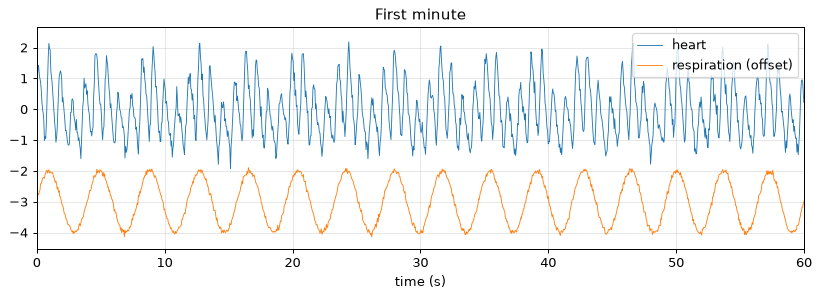

In [3]:
from fastmoda import load_signal

BASE = "https://raw.githubusercontent.com/st7ma784/MODA/main/example_sigs/"
for name in ("heart.mat", "resp.mat"):
    urllib.request.urlretrieve(BASE + name, name)

heart, _ = load_signal("heart.mat")
resp, _ = load_signal("resp.mat")
fs = 20.0                       # the files carry no sampling rate
t = np.arange(heart.size) / fs
print(f"{heart.size} samples, {heart.size / fs:.0f} s at {fs:g} Hz")

fig, ax = plt.subplots()
ax.plot(t, heart, lw=0.7, label="heart")
ax.plot(t, resp - 3, lw=0.7, label="respiration (offset)")
ax.set(xlim=(0, 60), xlabel="time (s)", title="First minute")
ax.legend(loc="upper right");

## 1. Time-frequency analysis

`wt_legacy` is MODA's `wt.m`. `f0` is MODA's resolution parameter and has no default: a larger
`f0` resolves frequency more sharply and time less sharply. With `cut_edges=True` (MODA's
default), cells outside the cone of influence are `NaN`.

WT: (195, 12000) 195 log-spaced bins, 0.051-2.98 Hz


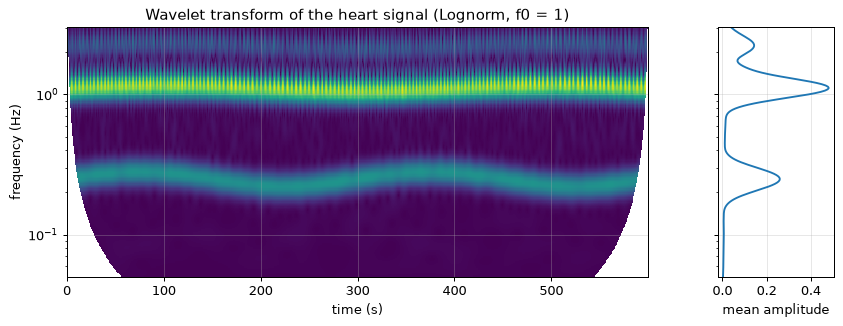

In [4]:
from fastmoda.legacy_moda import wt_legacy, wft_legacy

WT, freq = wt_legacy(heart, fs, fmin=0.05, fmax=3, f0=1.0)
print("WT:", WT.shape, f"{freq.size} log-spaced bins, {freq[0]:.3f}-{freq[-1]:.2f} Hz")

def tf_plot(W, f, title, log=True):
    fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [5, 1]},
                               sharey=True)
    step = 10                                     # plot every 10th sample
    a.pcolormesh(t[::step], f, np.abs(W[:, ::step]), shading="auto", cmap="viridis")
    a.set(xlabel="time (s)", ylabel="frequency (Hz)", title=title)
    b.plot(np.nanmean(np.abs(W), axis=1), f)
    b.set(xlabel="mean amplitude")
    if log:
        a.set_yscale("log")
    return fig

tf_plot(WT, freq, "Wavelet transform of the heart signal (Lognorm, f0 = 1)");

The heartbeat sits near 1.1 Hz, with its harmonic near 2.2 Hz. The direct respiratory component
is near 0.25 Hz and drifts slowly, as the breathing rate does by design. Breathing also changes
the heart rate within each breath. That's too fast to see at this resolution, but the ridge in
the next section picks it up.

`wft_legacy` is MODA's windowed Fourier transform (`wft.m`). It uses a linear frequency grid and
gives the same time resolution at every frequency:

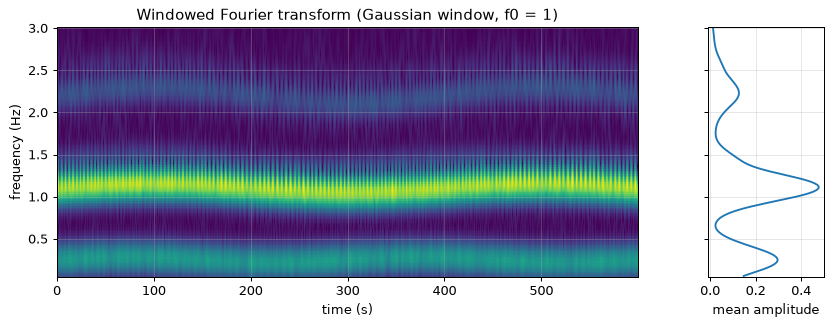

In [5]:
WFT, freqf = wft_legacy(heart, fs, fmin=0.05, fmax=3, f0=1.0)
tf_plot(WFT, freqf, "Windowed Fourier transform (Gaussian window, f0 = 1)", log=False);

## 2. Ridge extraction: heart rate and breathing rate

`extract_ridge_legacy` runs MODA's `ecurve` and then `rectfr`. Given a band, it traces the
dominant component through it and returns that component's instantaneous frequency, amplitude
and phase.

heart rate 66.8 bpm, breathing 15.0 breaths/min; corr(heart rate, respiration) = 0.75


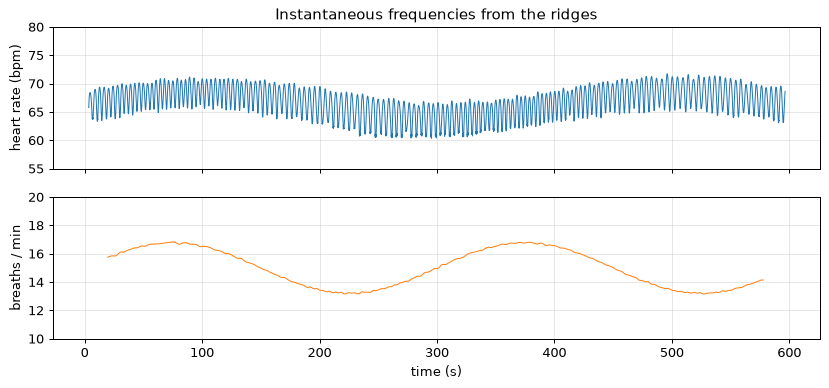

In [6]:
from fastmoda.legacy_ridge import extract_ridge_legacy, wavelet_constants

C, D = wavelet_constants("Lognorm", 1.0)

Wh, fh = wt_legacy(heart, fs, fmin=0.8, fmax=1.6, f0=1.0)
Wr, fr = wt_legacy(resp, fs, fmin=0.12, fmax=0.45, f0=1.0)
rh = extract_ridge_legacy(Wh, fh, fs, C, D)
rr = extract_ridge_legacy(Wr, fr, fs, C, D)

fig, ax = plt.subplots(2, 1, figsize=(11, 4.5), sharex=True)
ax[0].plot(t, 60 * rh["ifreq"], lw=0.8)
ax[0].set(ylabel="heart rate (bpm)", ylim=(55, 80),
          title="Instantaneous frequencies from the ridges")
ax[1].plot(t, 60 * rr["ifreq"], lw=0.8, color="C1")
ax[1].set(ylabel="breaths / min", ylim=(10, 20), xlabel="time (s)");

ok = np.isfinite(rh["ifreq"])
print(f"heart rate {60 * np.nanmean(rh['ifreq']):.1f} bpm, "
      f"breathing {60 * np.nanmean(rr['ifreq']):.1f} breaths/min; "
      f"corr(heart rate, respiration) = {np.corrcoef(rh['ifreq'][ok], resp[ok])[0, 1]:.2f}")

The heart rate swings up and down with every breath: this is respiratory sinus arrhythmia, and
it shows up as a positive correlation between the heart rate and the respiration signal.
Underneath, both rates drift slowly over minutes, as the signals were built to.

## 3. Wavelet phase coherence

`wphcoh_legacy` is MODA's `wphcoh.m`: for each frequency, how consistently the two phases stay
locked over the whole recording. To decide what counts as significant, we compute the
coherence of the heart signal against IAAFT surrogates of respiration. Surrogates keep
respiration's spectrum but destroy any phase relationship with the heart. Pass transforms
with `cut_edges=False`, because coherence handles the edges itself.

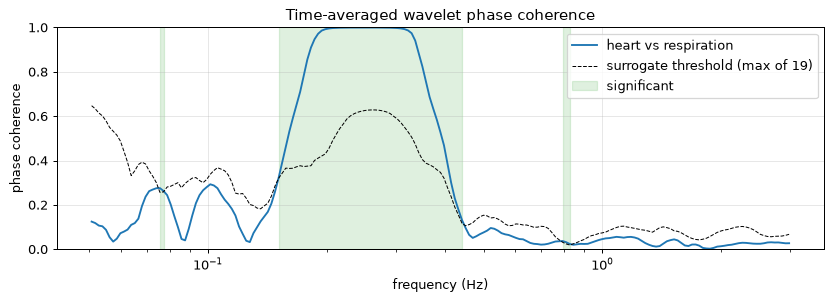

In [7]:
from fastmoda.legacy_moda import wphcoh_legacy
from fastmoda.surrogates import iaaft_surrogate

kw = dict(fmin=0.05, fmax=3, f0=1.0, cut_edges=False)
W1, fc = wt_legacy(heart, fs, **kw)
W2, _ = wt_legacy(resp, fs, **kw)
phcoh, phdiff = wphcoh_legacy(W1, W2)

surr = np.array([wphcoh_legacy(W1, wt_legacy(iaaft_surrogate(resp, seed=k), fs, **kw)[0])[0]
                 for k in range(19)])
threshold = surr.max(axis=0)        # MODA's "Maximum": 19 surrogates gives the 95% level

fig, ax = plt.subplots()
ax.semilogx(fc, phcoh, label="heart vs respiration")
ax.semilogx(fc, threshold, "k--", lw=0.8, label="surrogate threshold (max of 19)")
ax.fill_between(fc, 0, 1, where=phcoh > threshold, color="C2", alpha=0.15,
                label="significant")
ax.set(xlabel="frequency (Hz)", ylabel="phase coherence", ylim=(0, 1),
       title="Time-averaged wavelet phase coherence")
ax.legend();

The coherence is significant around the breathing frequency, because respiration feeds
straight into the heart trace there. At the heart's own frequency, respiration has almost no
power, so its phase there is noise and the coherence is not significant.

## 4. Wavelet bispectrum and biphase

The bispectrum looks for **quadratic** (frequency-mixing) coupling, where components at `f1`
and `f2` produce one at `f1 + f2` whose phase is locked to theirs. Respiration modulating the
heartbeat's amplitude and rate does exactly this: it puts sidebands at 1.1 ± 0.25 Hz into the
heart signal. The heart signal's own bispectrum therefore peaks at (breathing, heartbeat).

`bispec_wav_legacy` is MODA's `bispecWavNew.m`. It needs about ½·N² extra transforms for N
frequency bins, so we use five minutes of signal and a narrow band.

Here `f0 = 2` rather than 1. The sideband at 1.35 Hz sits only 0.25 Hz from the much
stronger heartbeat at 1.1 Hz. At `f0 = 1` the wavelet is too broad to tell them apart, so the
"sideband" phase would really be the heartbeat's.

222 x 222 bispectrum in 11 s
peak at f1 = 0.26 Hz, f2 = 1.14 Hz


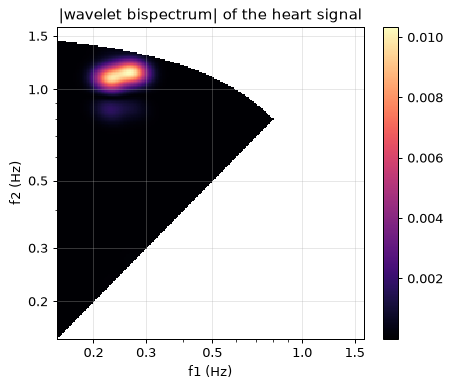

In [8]:
from fastmoda.legacy_moda import bispec_wav_legacy, biphase_wav_legacy
from matplotlib.ticker import FixedLocator, NullFormatter, ScalarFormatter

seg = slice(0, int(300 * fs))
bkw = dict(fmin=0.15, fmax=1.6, f0=2.0)
t0 = time.time()
B, fb, opt, _, _ = bispec_wav_legacy(heart[seg], heart[seg], fs, **bkw)
print(f"{fb.size} x {fb.size} bispectrum in {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
m = ax.pcolormesh(fb, fb, np.abs(B).T, shading="auto", cmap="magma")
ax.set(xscale="log", yscale="log", xlabel="f1 (Hz)", ylabel="f2 (Hz)",
       title="|wavelet bispectrum| of the heart signal")
for a in (ax.xaxis, ax.yaxis):
    a.set_major_locator(FixedLocator([0.2, 0.3, 0.5, 1.0, 1.5]))
    a.set_major_formatter(ScalarFormatter()); a.set_minor_formatter(NullFormatter())
fig.colorbar(m);

j, k = np.unravel_index(np.nanargmax(np.abs(B)), B.shape)
print(f"peak at f1 = {fb[j]:.2f} Hz, f2 = {fb[k]:.2f} Hz")

The **biphase** at the peak, φ(f1) + φ(f2) − φ(f1 + f2), shows whether the three components
stay phase-locked over time. If they do, it stays nearly constant, which indicates real
quadratic coupling rather than three unrelated oscillations that happen to sit at those
frequencies. Without coupling, it would wind steadily round the circle.

biphase std over 260 s: 0.20 rad


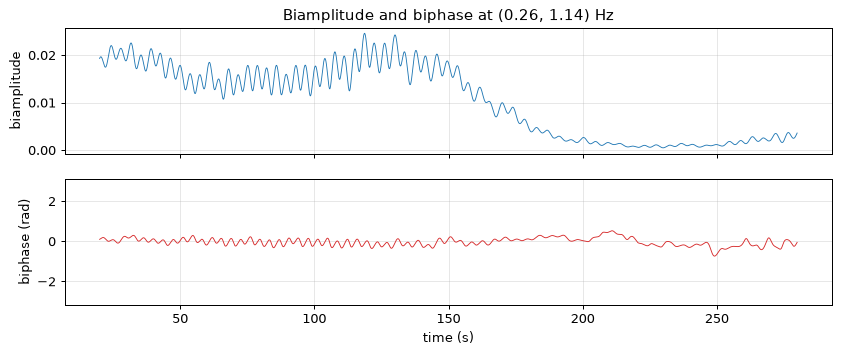

In [9]:
biamp, biphase = biphase_wav_legacy(heart[seg], heart[seg], fs, fb[j], fb[k], **bkw)
ok = np.isfinite(biphase)
print(f"biphase std over {ok.sum() / fs:.0f} s: {np.std(biphase[ok]):.2f} rad")

fig, ax = plt.subplots(2, 1, figsize=(11, 4), sharex=True)
ax[0].plot(t[seg], biamp, lw=0.7); ax[0].set(ylabel="biamplitude",
          title=f"Biamplitude and biphase at ({fb[j]:.2f}, {fb[k]:.2f}) Hz")
ax[1].plot(t[seg], biphase, lw=0.7, color="C3")
mid = np.nanmedian(biphase)
ax[1].set(ylabel="biphase (rad)", xlabel="time (s)", ylim=(mid - np.pi, mid + np.pi));

## 5. Dynamical Bayesian inference: who drives whom?

Coherence and the bispectrum show that the signals interact, but not in which direction.
`full_bayesian` (MODA's `full_bayesian.m`) does the following:

- band-passes each signal around its oscillation and takes its phase;
- fits a model of how each phase drives the other, window by window;
- tests each direction against cyclic-phase-permutation surrogates.

The arguments are the same as in MODA's Bayesian GUI.

12 windows, filter orders 9 / 5, 1 s


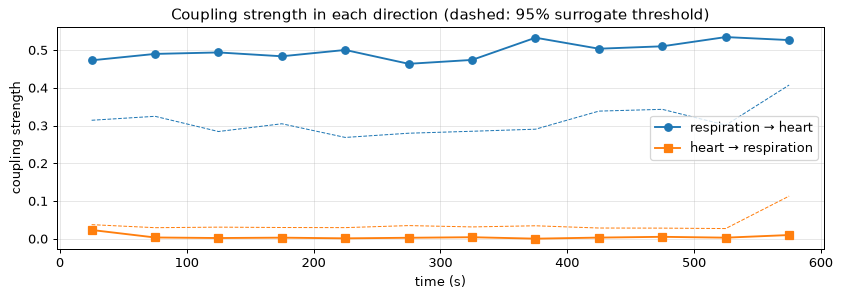

In [10]:
from fastmoda.legacy_bayes import full_bayesian

t0 = time.time()
fb_ = full_bayesian(heart, resp,
                    (0.8, 1.5), (0.15, 0.4),   # heart band, respiration band (Hz)
                    fs,
                    50,      # window (s)
                    0.2,     # propagation constant
                    1,       # window step, as a fraction of the window
                    2,       # Fourier order of the coupling basis
                    19,      # surrogates
                    95)      # significance (%)
print(f"{fb_['tm'].size} windows, filter orders {fb_['order1']} / {fb_['order2']}, "
      f"{time.time() - t0:.0f} s")

fig, ax = plt.subplots()
ax.plot(fb_["tm"], fb_["cpl1"], "o-", label="respiration → heart")
ax.plot(fb_["tm"], fb_["surr_cpl1"], "C0--", lw=0.8)
ax.plot(fb_["tm"], fb_["cpl2"], "s-", color="C1", label="heart → respiration")
ax.plot(fb_["tm"], fb_["surr_cpl2"], "C1--", lw=0.8)
ax.set(xlabel="time (s)", ylabel="coupling strength",
       title="Coupling strength in each direction (dashed: 95% surrogate threshold)")
ax.legend();

Respiration → heart sits well above its surrogate threshold in every window. Heart →
respiration does not. The analysis recovers the direction the signals were built with.

The **coupling function** shows *how* respiration acts on the heart: the effect on the heart's
phase velocity at each combination of the two phases.

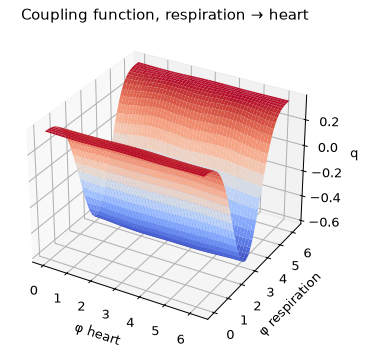

In [11]:
cf = fb_["mcf1"]                     # time-averaged, respiration → heart; cf[i, j] at (φ_heart[i], φ_resp[j])
phi = 0.13 * np.arange(cf.shape[0])  # MODA's 0:0.13:2π grid
fig = plt.figure(figsize=(6, 4.5))
ax = fig.add_subplot(projection="3d")
P1, P2 = np.meshgrid(phi, phi, indexing="ij")
ax.plot_surface(P1, P2, cf, cmap="coolwarm", linewidth=0)
ax.set(xlabel="φ heart", ylabel="φ respiration", zlabel="q",
       title="Coupling function, respiration → heart");

The function varies only along the respiration phase, as a single sine wave: breathing speeds
the heart up in one half of the breath and slows it down in the other. Its amplitude, about
0.5 rad/s, is the 2π × 0.08 the heart signal was built with.

## 6. Changepoints

These are FastMODA's own tools and have no MODA counterpart. To have something to find, we
make a copy of the heart signal in which the heartbeat weakens to 40 % after 400 s.

- `changepoints_at_frequency` follows the power at one frequency. Here that's the heartbeat.
- `changepoints_logbinned_power` watches the whole spectrum in log-spaced bands, and reports
  a change in any of them.

power at 1.09 Hz:      405 s
log-binned power:            180 s, 292 s, 405 s
log-binned, unmodified heart: 155 s, 242 s, 342 s, 442 s


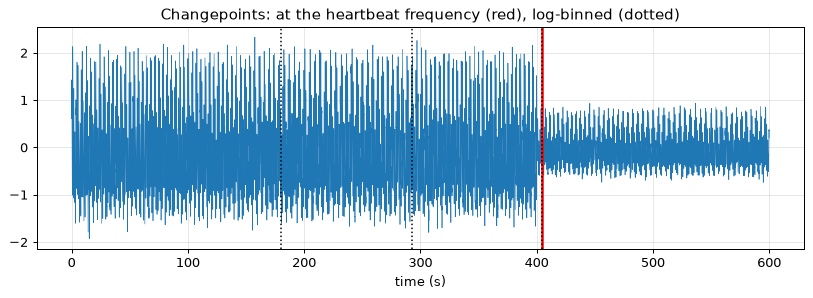

In [12]:
from fastmoda.changepoint import changepoints_at_frequency, changepoints_logbinned_power

x = heart.copy()
x[t > 400] *= 0.4

at_heart = changepoints_at_frequency(x, 1.1, fs=fs, win_s=10.0)
binned = changepoints_logbinned_power(x, fs=fs, win_s=10.0, n_bins=12, fmin=0.1, fmax=3)
binned0 = changepoints_logbinned_power(heart, fs=fs, win_s=10.0, n_bins=12, fmin=0.1, fmax=3)
fmt = lambda cp: ", ".join(f"{c:.0f} s" for c in cp["changepoint_times"]) or "none"
print(f"power at {at_heart['actual_freq']:.2f} Hz:      {fmt(at_heart)}")
print(f"log-binned power:            {fmt(binned)}")
print(f"log-binned, unmodified heart: {fmt(binned0)}")

fig, ax = plt.subplots()
ax.plot(t, x, lw=0.5)
for c in at_heart["changepoint_times"]:
    ax.axvline(c, color="r", lw=2, label="at 1.1 Hz")
for c in binned["changepoint_times"]:
    ax.axvline(c, color="k", ls=":", lw=1.2)
ax.set(xlabel="time (s)", title="Changepoints: at the heartbeat frequency (red), log-binned (dotted)");

The heartbeat frequency gives exactly the planted change. The log-binned search finds it as
well, along with other changes that it also finds in the unmodified signal. Those come from
the signals' own slow drift in rate, which is built into them, so they are real changes in
the spectrum, just not the one we planted. Which detector to use depends on whether you care
about one rhythm or the whole spectrum.

## 7. Features for the condition classifiers

`compute_feature_vector` turns a recording into the fixed-length vector that FastMODA's
condition classifiers score. It includes spectral, phase, STFT, wavelet (from `wt_legacy`)
and bispectral features.

In [13]:
import warnings
from collections import defaultdict
from fastmoda.pipeline import compute_feature_vector, FEATURE_SET

with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)   # NaN-only rows in some feature groups
    vec, names = compute_feature_vector(heart, fs)

groups = defaultdict(list)
for n, v in zip(names, vec):
    groups[n.split("_")[0]].append((n, v))
print(f"{len(vec)} features, feature set '{FEATURE_SET}'. Two from each group:")
for g, items in groups.items():
    print(f"\n{g} ({len(items)})")
    for n, v in items[:2]:
        print(f"  {n:42s} {v: .4g}")

68 features, feature set 'moda-wt-v1'. Two from each group:

bispectrum (10)
  bispectrum_coupling_entropy                 7.484
  bispectrum_max_bicoherence                  2.25e+11

phase (15)
  phase_amp_modulation_index                  4.608
  phase_amp_range                             2.491

spectral (18)
  spectral_alpha_power                        0.3535
  spectral_beta_power                         0

stft (9)
  stft_centroid_trend                        -3.356e-05
  stft_mean_spectral_flux                     0.1112

wavelet (16)
  wavelet_high_scale_energy_ratio             0.1168
  wavelet_low_scale_energy_ratio              0.5629


To score a vector, install `fastmoda[ml]` and call
`fastmoda.condition_models.classify(vec, names, model_dir=...)`. No models come with the
package. Train them on your own labelled recordings with
`FastMODA/scripts/train_condition_classifiers.py` from the repository (see
[Training a Classifier](https://st7ma784.github.io/MODA/api-and-ml/training-a-classifier/)).

## Where next

- [The Python Library](https://st7ma784.github.io/MODA/api-and-ml/python-library/): every
  function, its arguments and its MODA original
- [Algorithms](https://st7ma784.github.io/MODA/algorithms/time-frequency-analysis/): what each
  analysis computes
- [Citations](https://st7ma784.github.io/MODA/reference/citations/): if you use this in
  research, cite MODA and the papers for the methods you used